C:\Users\fuzzb\miniforge3\envs\gsc\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


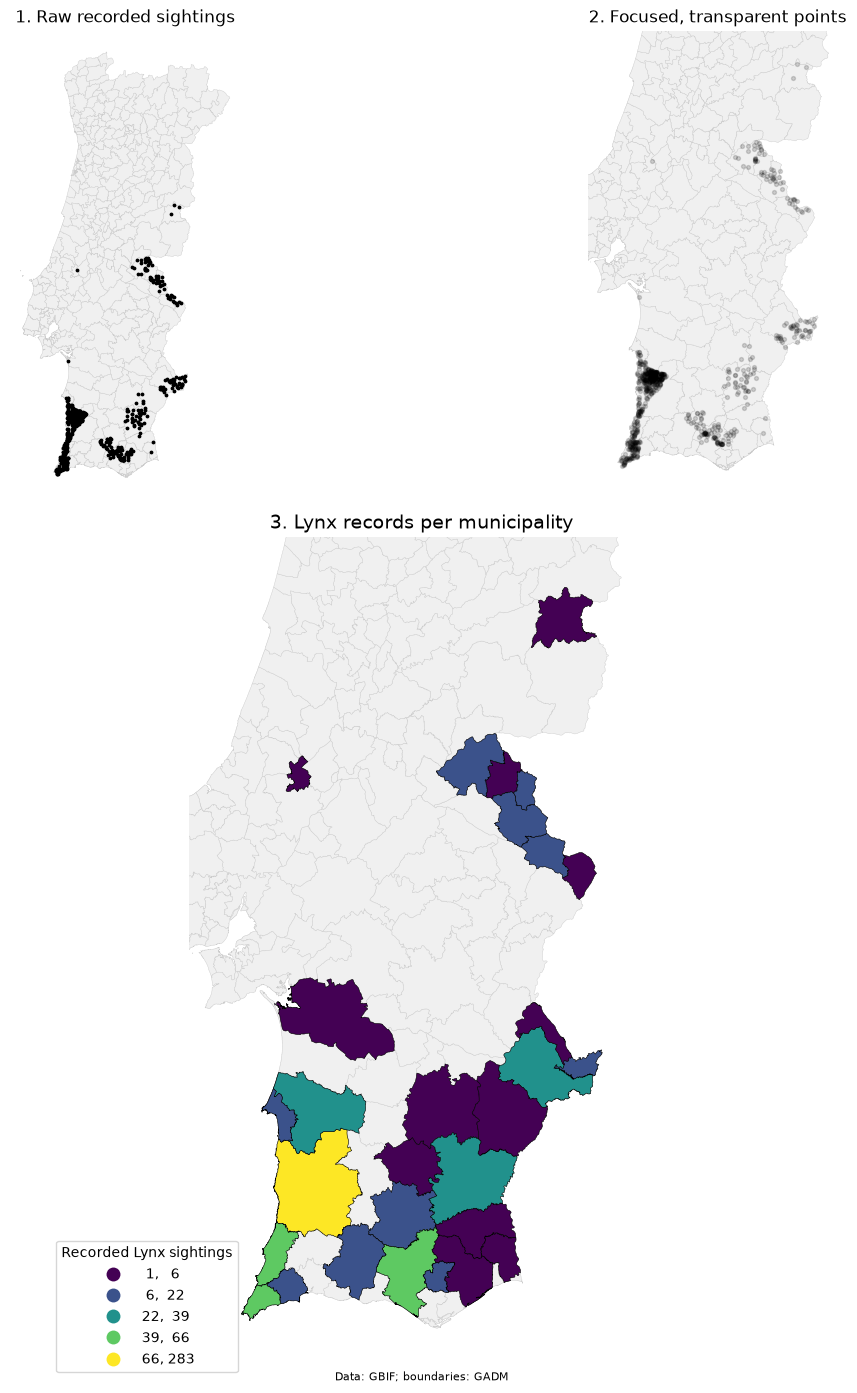

In [8]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon

# creating file routes
filepath = 'Portugal_M.gpkg'
portugal_gdf = gpd.read_file(filepath, layer="ADM_ADM_2")

# dropping the exptremitites (Azores etc.) to leave only mainland portugal
portugal_gdf = portugal_gdf[~portugal_gdf["NAME_1"].isin(["Azores", "Madeira"])]

filepath2 = 'lynx.csv'
df = pd.read_csv(filepath2, sep="\t", low_memory=False)

# removing rows that dont have any coordinate data
df = df.dropna(subset=["decimalLongitude", "decimalLatitude"])

# converting to GeoDataFrame
lynx_gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["decimalLongitude"], df["decimalLatitude"]),
    crs="EPSG:4326",
)

lynx_gdf = lynx_gdf.to_crs("EPSG:3763")
portugal_gdf = portugal_gdf.to_crs("EPSG:3763")

# creating a count for recorded Lynx sightings per municipality
joined = gpd.sjoin(
    lynx_gdf,
    portugal_gdf[["geometry"]],
    how="inner",
    predicate="within",
)

counts = joined["index_right"].value_counts()

#populating na as an integer
portugal_gdf["n_records"] = portugal_gdf.index.map(counts).fillna(0).astype(int)


##creating the graphs

# correctng the bounds of the projection
minx, miny, maxx, maxy = lynx_gdf.total_bounds
pad = 30_000 
xlim = (minx - pad, maxx + pad)
ylim = (miny - pad, maxy + pad)

#creating appropriate layout
fig, axes = plt.subplot_mosaic(
    [["A", "B"],
     ["C", "C"]],
    figsize=(12, 14),
    height_ratios=[1, 1.8],
)


# 1. Initial raw data projected on mainland portugal
portugal_gdf.plot(ax=axes["A"], color="#f0f0f0", edgecolor="#cccccc", linewidth=0.3)
lynx_gdf.plot(ax=axes["A"], color="black", markersize=3)
axes["A"].set_title("1. Raw recorded sightings")

# 2. Zoomed in for clarity, using semi-transparent points so overlaps build up darker
portugal_gdf.plot(ax=axes["B"], color="#f0f0f0", edgecolor="#cccccc", linewidth=0.3)
lynx_gdf.plot(ax=axes["B"], color="black", markersize=8, alpha=0.15)
axes["B"].set_xlim(xlim)
axes["B"].set_ylim(ylim)
axes["B"].set_title("2. Focused, transparent points")

# 3.choropleth plot 
# collating only the municipalities that have recorded sightings 
has_records = portugal_gdf[portugal_gdf["n_records"] > 0]

portugal_gdf.plot(ax=axes["C"], color="#f0f0f0", edgecolor="#cccccc", linewidth=0.3)
has_records.plot(
    column="n_records",
    cmap="viridis",
    scheme="naturalbreaks",
    k=5,
    edgecolor="black",
    linewidth=0.4,
    legend=True,
    legend_kwds={
        "loc": "lower left",
        "bbox_to_anchor": (-0.3, 0),
        "title": "Recorded Lynx sightings",
        "fmt": "{:.0f}"},
    ax=axes["C"],
)

axes["C"].set_xlim(xlim)
axes["C"].set_ylim(ylim)
axes["C"].set_title("3. Lynx records per municipality", fontsize=14)

#cleaning up the images by removing the scales
for ax in axes.values():
    ax.set_axis_off()

# adding citation for data source
fig.text(0.5, 0.01, "Data: GBIF; boundaries: GADM", ha="center", fontsize=8)

plt.tight_layout()
plt.show()


#saving the image
fig.savefig("lynx_observations.png", dpi=300, bbox_inches="tight")